# Köhler and critical illumination: where to put the image of the lamp

A microscope lamp is a coiled filament: bright ribbons with dark gaps
between them. The illuminator has to turn it into an evenly lit field on
the specimen, with a cone of light that fills the objective's aperture to a
chosen fraction. Two classic answers differ in one choice, where the
collector images the filament:

- **critical (Nelson) illumination:** onto the field diaphragm, and with it
  onto the specimen. Simple, bright, and the specimen is lit by the image of
  the filament, ribbons and gaps included.
- **Köhler illumination** (1893): into the aperture diaphragm in the front
  focal plane of the condenser. Every point of the filament then becomes a
  plane wave through the specimen, every point of the specimen receives
  light from the whole filament, and the field is even. The field diaphragm
  sits in a plane conjugate to the specimen and sets the size of the lit
  field; the aperture diaphragm sets the illumination NA. The two controls
  are independent.

Notebook 52 used Köhler illumination as given: a set of plane waves, one per
point of the condenser aperture. Here we build the illuminator and trace
it. Irradiance is computed by **backward ray tracing**
(`il.backward_irradiance()`): by the brightness theorem of notebook 83 the
irradiance at a point is $E = \int L\,dp\,dq$ over the directions of the
light arriving there, and the radiance carried by a ray is that of the
source point it comes from. So we trace rays from the specimen backwards
through the reversed system (`il.reverse_system()`) and look up where they
land on the filament (`il.backward_trace()`). This is far more efficient
than tracing rays forward from the lamp and counting the few that pass two
small diaphragms.

The sections: the illuminator and its two lamp positions (1), forward
against backward tracing and the étendue budget (2), the lit field and the
directions of the light (3), the phase space at the specimen (4), what each
diaphragm does (5), moving the lamp from one setting to the other (6), and
the image of a Siemens star under both (7).

The microscope of notebook 52, with the illumination ray path:

In [1]:
import copy
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from pyoptics import illumination as il
from pyoptics import microscopy as mic
from pyoptics import raytrace as rt
from pyoptics import sketch
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(85)

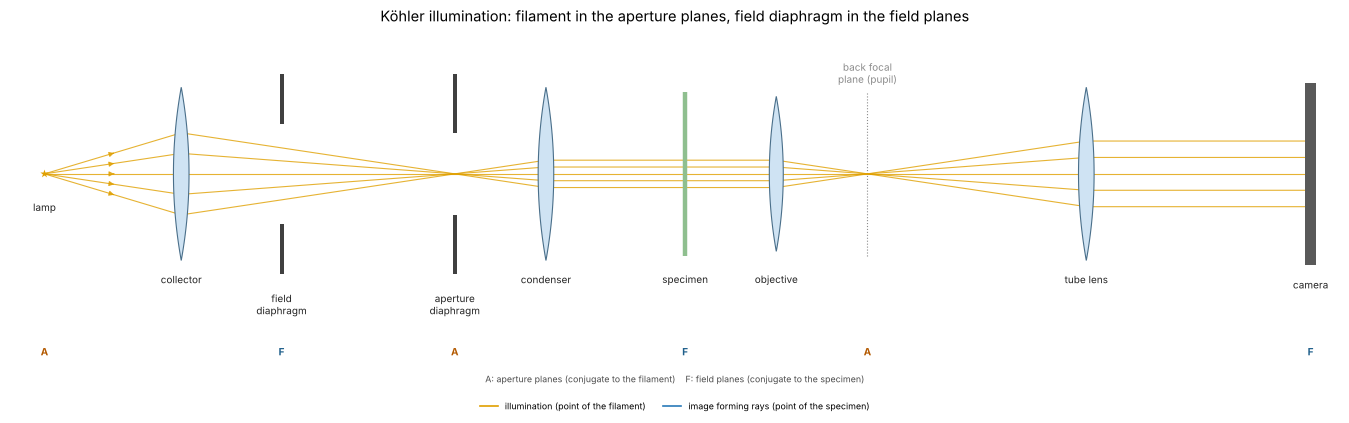

In [2]:
fig, ax = plt.subplots(figsize=(17, 5.6))
sketch.koehler_microscope(ax, rays="illumination", title="Köhler illumination: filament in the aperture planes, field diaphragm in the field planes")
plt.tight_layout()
plt.show()

## 1. The illuminator

Sketched first, with thin lenses: the same collector, diaphragms and
condenser, and only the lamp moved. Close to the collector, the filament
is imaged into the aperture diaphragm (Köhler); further back, into the
field diaphragm (critical).

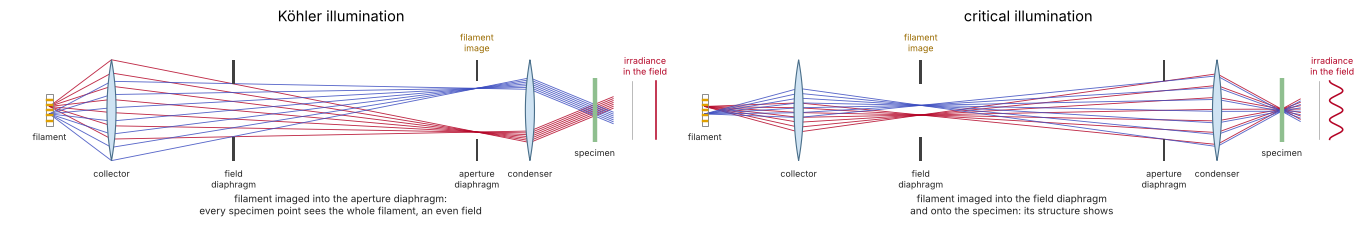

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6), layout="constrained")
sketch.koehler_critical(ax[0], "koehler", title="Köhler illumination")
sketch.koehler_critical(ax[1], "critical", title="critical illumination")
plt.show()

The traced system consists of glass lenses with $n = 1.5$:

- **collector:** a plano-convex lens with a hyperbolic face ($K = -n^2$,
  $f = 20$ mm), turned to the lamp. It collimates a point at its focus
  without spherical aberration.
- **field diaphragm:** 40 mm behind the collector, radius 2 mm.
- **field lens:** the same type of lens with $f = 100$ mm, at its focal
  distance from the field diaphragm, so that the light from every point of
  the diaphragm is collimated.
- **aperture diaphragm:** radius 3 mm, in the front focal plane of the
  condenser.
- **condenser:** a hyperbolic plano-convex lens with $f = 10$ mm, flat
  side first. It focuses collimated light without spherical aberration.

The field lens matters: a first version without it put the field diaphragm
100 mm in front of the condenser, and the condenser's spherical aberration
at that finite conjugate blurred the edge of the field by 150 µm. The
specimen sits in the image of the field diaphragm, $m = -f_\text{cond}/f_\text{field} = -0.1$.
The filament has seven ribbons, 0.25 mm wide and 4 mm high, at a pitch of
0.5 mm. `brentq` finds the two lamp positions.

In [4]:
N_GLASS = 1.5

def hyperbolic(f, sd, t, flat_first=True):
    """Plano-convex lens with a hyperbolic face (K = -n^2). Flat side first, it focuses
    collimated light without spherical aberration; turned round, it collimates its focus."""
    R, K = (N_GLASS - 1)*f, -N_GLASS**2
    if flat_first:
        return [rt.Surface(np.inf, t, n_after=N_GLASS, semi_diameter=sd),
                rt.Surface(-R, 0.0, n_after=1.0, conic=K, semi_diameter=sd)]
    return [rt.Surface(R, t, n_after=N_GLASS, conic=K, semi_diameter=sd),
            rt.Surface(np.inf, 0.0, n_after=1.0, semi_diameter=sd)]

def collector():
    return hyperbolic(20.0, 12.0, 9.0, flat_first=False)

def condenser():
    return hyperbolic(10.0, 6.0, 5.0, flat_first=True)

def axis_crossing(surfaces, P, d):
    """Distance behind the last vertex where a near-axis ray crosses the axis."""
    S = [copy.copy(s) for s in surfaces]
    S[-1].thickness = 0.0
    B = rt.System(S, 0, 550e-6, object_distance=1.0, object_height=1.0).trace(rt.Rays(P, d, np.zeros(1)), clip=False)
    p, e = B.points[-1][0], B.directions[-1][0]
    return p[2] - sum(s.thickness for s in S) - p[1]/e[1]*e[2]

def image_distance(surfaces, s_obj, u=1e-4):
    return axis_crossing(surfaces, np.array([[0, 0, -s_obj]]), np.array([[0, np.sin(u), np.cos(u)]]))

FFL = 10.0 - 5.0/N_GLASS             # front focal distance of the condenser (flat side first)
F_FIELD, T_FIELD, GAP = 100.0, 3.0, 4.0

def field_lens():
    """Collimates the light from each point of the field diaphragm, so that the condenser,
    which is free of spherical aberration for a collimated input, images the diaphragm sharply."""
    S = hyperbolic(F_FIELD, 10.0, T_FIELD, flat_first=False)
    S[-1].thickness = GAP
    return S

def condenser_group():
    A = field_lens()
    A[-1].thickness = GAP + FFL
    return A + condenser()

G_FD = 40.0                          # collector -> field diaphragm
FD_A = F_FIELD                       # field diaphragm in the front focal plane of the field lens
Z_AD = G_FD + FD_A + T_FIELD + GAP   # aperture diaphragm in the front focal plane of the condenser
S_CRIT = brentq(lambda s: image_distance(collector(), s) - G_FD, 20.001, 400)       # filament imaged on the FD
def _coll_A():
    S = collector()
    S[-1].thickness = G_FD + FD_A
    return S + field_lens()
S_KOEHLER = brentq(lambda s: image_distance(_coll_A(), s) - GAP, 20.001, S_CRIT)    # ... on the AD
SPEC = image_distance(condenser_group(), FD_A)

def illuminator(s_lamp, r_fd=2.0, r_ad=3.0):
    S = collector()
    S[-1].thickness = G_FD
    S += [rt.Surface(np.inf, FD_A, semi_diameter=r_fd, label="field diaphragm")]
    S += field_lens()
    S += [rt.Surface(np.inf, FFL, semi_diameter=r_ad, label="aperture diaphragm")]
    C = condenser()
    C[-1].thickness = SPEC
    return rt.System(S + C, 5, 550e-6, object_distance=s_lamp, object_height=1.75)

# the coiled filament: 7 vertical ribbons 0.25 mm wide, 0.5 mm apart, 4 mm high
N_RIB, W_RIB, PITCH, H_FIL = 7, 0.25, 0.5, 4.0

def filament(x, y):
    u = x/PITCH + (N_RIB - 1)/2
    k = np.round(u)
    return (np.abs(u - k)*PITCH <= W_RIB/2) & (k >= 0) & (k <= N_RIB - 1) & (np.abs(y) <= H_FIL/2)

koehler, critical = illuminator(S_KOEHLER), illuminator(S_CRIT)
# paraxial magnifications from the ABCD matrices of the traced systems
def magnification(s_obj, surfaces):
    S = [copy.copy(s) for s in surfaces]
    S[-1].thickness = image_distance(surfaces, s_obj)
    return rt.System(S, 0, 550e-6, object_distance=s_obj, object_height=1.0).paraxial().magnification

M_COLL_K = magnification(S_KOEHLER, _coll_A())
M_COLL_C = magnification(S_CRIT, collector())
M_COND = magnification(FD_A, condenser_group())
NA_C = 3.0/10.0
print("lamp to collector: Köhler {:.2f} mm, critical {:.2f} mm".format(S_KOEHLER, S_CRIT))
print("collector magnification: Köhler (filament -> AD, with the field lens) {:.2f}, critical (filament -> FD) {:.2f}".format(M_COLL_K, M_COLL_C))
print("field lens + condenser: FD -> specimen {:.4f}, specimen {:.2f} mm behind the condenser; NA of the AD (r = 3 mm, f = 10 mm): {:.2f}"
      .format(M_COND, SPEC, NA_C))

lamp to collector: Köhler 23.02 mm, critical 35.38 mm
collector magnification: Köhler (filament -> AD, with the field lens) -6.22, critical (filament -> FD) -1.30
field lens + condenser: FD -> specimen -0.1000, specimen 10.00 mm behind the condenser; NA of the AD (r = 3 mm, f = 10 mm): 0.30


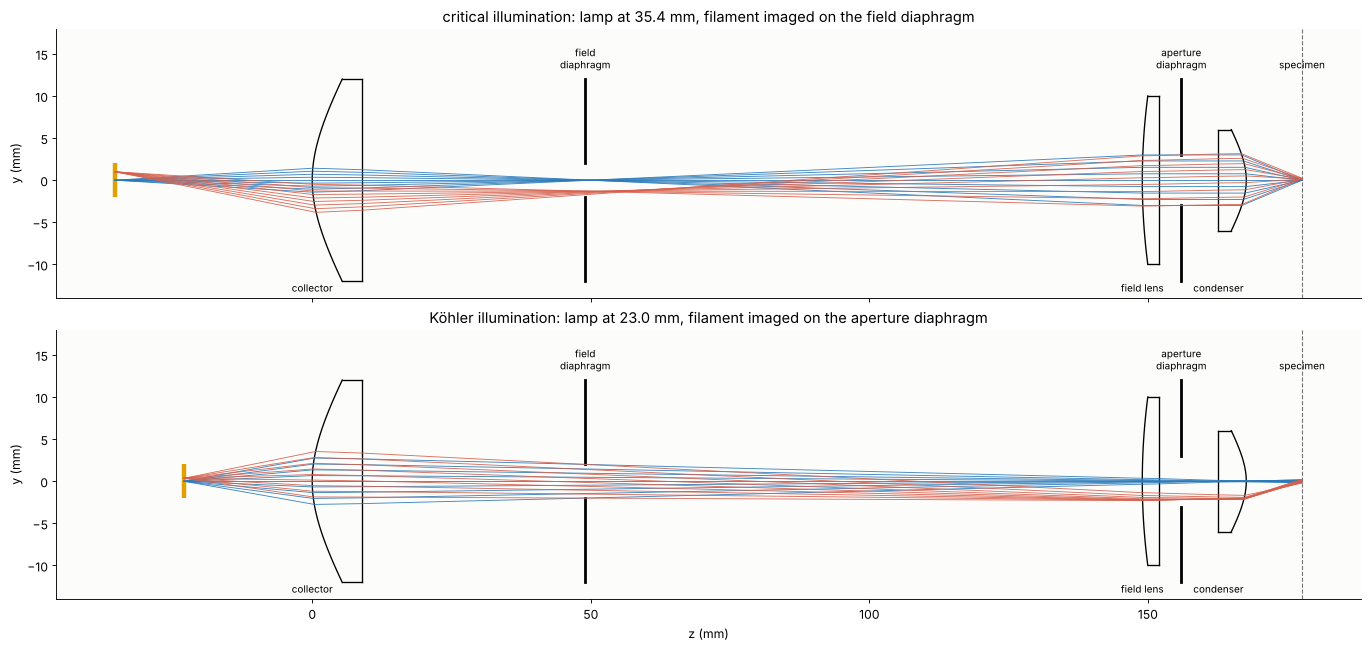

In [5]:
def draw_layout(ax, S, fields, colors, na=0.45, n_rays=13):
    z = -S.object_distance
    ax.plot([z, z], [-H_FIL/2, H_FIL/2], color=ORANGE, lw=4, solid_capstyle="butt")
    zv = np.concatenate([[0.0], np.cumsum([s.thickness for s in S.surfaces])])
    n = S.n
    for i, s in enumerate(S.surfaces):
        r = np.linspace(-s.semi_diameter, s.semi_diameter, 101)
        if n[i + 1] != n[i]:
            ax.plot(zv[i] + s.sag(r**2), r, color="k", lw=1.2)
            if n[i + 1] == 1.0:   # back of a lens: close the rim
                for sgn in (1, -1):
                    ax.plot([zv[i - 1] + S.surfaces[i - 1].sag(s.semi_diameter**2), zv[i] + s.sag(s.semi_diameter**2)],
                            [sgn*s.semi_diameter]*2, color="k", lw=1.2)
        else:
            for sgn in (1, -1):
                ax.plot([zv[i]]*2, [sgn*s.semi_diameter, sgn*12], color="k", lw=2.5)
            ax.text(zv[i], 13, s.label.replace(" diaphragm", "\ndiaphragm"), ha="center", va="bottom", fontsize=9)
    ax.axvline(zv[-1], color=GREY, lw=1, ls="--")
    ax.text(zv[-1], 13, "specimen", ha="center", va="bottom", fontsize=9)
    for y0, c in zip(fields, colors):
        # many rays from the filament point; draw a few of those that reach the specimen
        u = np.linspace(-na, na, 4001)
        P = np.column_stack([0*u, np.full(len(u), y0), np.full(len(u), z)])
        B = S.trace(rt.Rays(P, il.directions_from_sines(0*u, u), np.zeros(len(u))))
        pts = B.points
        ok = np.flatnonzero(np.all(np.isfinite(pts[:, :, 2]), axis=0))
        if len(ok) == 0:
            continue
        for j in ok[np.linspace(0, len(ok) - 1, n_rays).round().astype(int)]:
            ax.plot(pts[:, j, 2], pts[:, j, 1], color=c, lw=0.8, alpha=0.9)
    for zl, txt in [(zv[0], "collector"), (zv[3], "field lens"), (zv[6], "condenser")]:
        ax.text(zl, -13.5, txt, ha="center", va="bottom", fontsize=9)
    ax.set_ylim(-14, 18)
    ax.set_ylabel("y (mm)")

fig, ax = plt.subplots(2, 1, figsize=(17, 8), layout="constrained", sharex=True)
for a, (name, S, y1) in zip(ax, [("critical illumination: lamp at {:.1f} mm, filament imaged on the field diaphragm".format(S_CRIT), critical, 1.0),
                                 ("Köhler illumination: lamp at {:.1f} mm, filament imaged on the aperture diaphragm".format(S_KOEHLER), koehler, 0.35)]):
    draw_layout(a, S, [0.0, y1], [BLUE, RED], n_rays=9)
    a.set_title(name)
ax[1].set_xlabel("z (mm)")
plt.show()

Drawn are rays from the centre of the filament (blue) and from a point
1 mm (critical) or 0.35 mm (Köhler) off-centre (red), only those that
pass both diaphragms. In critical illumination each filament point is
imaged onto the specimen, a different point for each. In Köhler
illumination the rays from one filament point are parallel at the
specimen and fill the whole field, and the filament image, 6.2 times
magnified, is cut by the 3 mm aperture diaphragm: only the inner part of
the filament (±0.48 mm) lights the specimen at all.

## 2. Forward against backward tracing, and the étendue budget

The check of the method: four million rays traced forward from the
filament (Lambertian within NA 0.55, in batches), counted in a disk of
100 µm radius at the centre of the field, against the backward trace from
1000 points of the same disk with 2000 directions each. Both are in units
of the filament radiance $L$.

A uniform source that filled the aperture diaphragm would give
$E = \Omega_\text{AD}L$, where $\Omega_\text{AD}$ is the projected solid
angle of the diaphragm seen from the specimen. A filament fills only part
of the diaphragm with its image, so Köhler illumination gives
$E = \text{fill}\cdot\Omega_\text{AD}L$. The fill follows from the paraxial
filament image, the ribbons scaled by the magnification of collector and
field lens.

In [6]:
Rk, Rc = il.reverse_system(koehler), il.reverse_system(critical)
NA_S = 0.33                     # contains all the light at the specimen
# forward Monte Carlo check at the centre of the field: rays from the filament, counted in a small disk
N_F, N_BATCH = 4_000_000, 500_000      # traced in batches to keep the memory small
na_lamp = 0.55
area_fil = N_RIB*W_RIB*H_FIL
G_lamp = il.etendue_lambertian(area_fil, na_lamp)     # power emitted into na_lamp for unit radiance
r0 = 0.1
for name, S, R in [("Köhler", koehler, Rk), ("critical", critical, Rc)]:
    n_hit = 0
    for _ in range(N_F//N_BATCH):
        i = rng.integers(0, N_RIB, N_BATCH)
        xf = (i - (N_RIB - 1)/2)*PITCH + (rng.random(N_BATCH) - 0.5)*W_RIB
        yf = (rng.random(N_BATCH) - 0.5)*H_FIL
        d = il.lambertian_directions(N_BATCH, na_lamp, rng=rng)
        B = S.trace(rt.Rays(np.column_stack([xf, yf, np.full(N_BATCH, -S.object_distance)]), d, np.zeros(N_BATCH)))
        Q = S.to_image_frame(B.points[-1])
        n_hit += np.sum(np.hypot(Q[:, 0], Q[:, 1]) < r0)
    E_fwd = n_hit/N_F*G_lamp/(np.pi*r0**2)
    E_bwd = il.backward_irradiance(S, il.disk_points(1000, r0, rng), NA_S, filament, n_directions=2000, rng=rng,
                                   reversed_system=R).mean()
    print("{:8s}: mean irradiance within 100 µm of the centre, forward Monte Carlo {:.4f} L (± {:.4f}, {} rays), backward {:.4f} L"
          .format(name, E_fwd, E_fwd/np.sqrt(n_hit), n_hit, E_bwd))
# fill of the aperture diaphragm by the filament image (paraxial: ribbons scaled by M_COLL_K)
xa, ya = np.meshgrid(np.linspace(-3, 3, 1201), np.linspace(-3, 3, 1201))
inside = np.hypot(xa, ya) <= 3.0
fill = np.mean(filament(xa[inside]/M_COLL_K, ya[inside]/M_COLL_K))
always = lambda x, y: np.ones_like(x)
omega_ad = il.backward_irradiance(koehler, np.zeros((1, 2)), NA_S, always, n_directions=200_000, rng=rng,
                                  reversed_system=Rk)[0]
pr = np.linspace(0, NA_S, 3301)
na_rim = pr[il.backward_trace(koehler, np.zeros((len(pr), 2)), pr, 0*pr, always, reversed_system=Rk) > 0].max()
print("projected solid angle of the aperture diaphragm seen from the specimen: {:.4f} = pi ({:.4f})^2; rim ray NA {:.4f} "
      "(r/f = {:.2f}: the hyperbolic condenser does not obey the sine condition)".format(omega_ad, np.sqrt(omega_ad/np.pi), na_rim, NA_C))
NA_C = na_rim
print("paraxial fill of the AD by the filament image {:.3f}: E = fill * Omega L = {:.4f} L".format(fill, fill*omega_ad))

Köhler  : mean irradiance within 100 µm of the centre, forward Monte Carlo 0.1015 L (± 0.0023, 1917 rays), backward 0.1039 L


critical: mean irradiance within 100 µm of the centre, forward Monte Carlo 0.1192 L (± 0.0025, 2252 rays), backward 0.1199 L
projected solid angle of the aperture diaphragm seen from the specimen: 0.2244 = pi (0.2672)^2; rim ray NA 0.2672 (r/f = 0.30: the hyperbolic condenser does not obey the sine condition)
paraxial fill of the AD by the filament image 0.448: E = fill * Omega L = 0.1005 L


Forward and backward agree within the Monte Carlo error, in both
settings. The projected solid angle of the aperture diaphragm is
$\pi\,(0.267)^2$, not $\pi\,(r/f)^2 = \pi\,(0.30)^2$. The rim ray leaves the
condenser at NA 0.267, because a lens free of spherical aberration on axis
does not obey Abbe's sine condition $h = f\sin\theta'$ (notebook 83,
section 3). The image of the filament fills 45 % of the diaphragm, and
$\text{fill}\cdot\Omega_\text{AD}$ predicts the traced Köhler irradiance to
3 %. Critical illumination is brighter on the axis, because the image of
the central ribbon fills its cone completely. The brightness theorem caps
both settings: no illuminator gives more than $\Omega L$ for a given cone.

## 3. The lit field and the directions of the light

Irradiance maps of the specimen plane (81 × 81 points, 600 directions
each), profiles along $x$ (6000 directions), and the radiance against
direction $L(p, q)$ at two points of the field. The last is what an
observer looking up from the specimen through the condenser would see: the
"pupil" of the illumination, imaged in the back focal plane of the
objective (the A planes of the sketch).

In [7]:
n_side = 81
xs = np.linspace(-0.3, 0.3, n_side)
XX, YY = np.meshgrid(xs, xs)
pts = np.column_stack([XX.ravel(), YY.ravel()])
E_map = {}
for name, S, R in [("Köhler", koehler, Rk), ("critical", critical, Rc)]:
    E_map[name] = il.backward_irradiance(S, pts, NA_S, filament, n_directions=600, rng=rng,
                                         reversed_system=R).reshape(n_side, n_side)
# fine profiles along x
xp = np.linspace(-0.3, 0.3, 241)
E_prof = {name: il.backward_irradiance(S, np.column_stack([xp, 0*xp]), NA_S, filament, n_directions=6000,
                                       rng=rng, reversed_system=R)
          for name, S, R in [("Köhler", koehler, Rk), ("critical", critical, Rc)]}
r_field = 2.0*abs(M_COND)
for name, E in E_prof.items():
    c = np.abs(xp) < 0.7*r_field
    print("{:8s}: mean {:.4f} L, rms/mean in the central 70 % of the field {:.1%}, min/max {:.2f}"
          .format(name, E[c].mean(), E[c].std()/E[c].mean(), E[c].min()/E[c].max()))
print("field radius = |m| r_FD = {:.3f} mm".format(r_field))
# pupils: directions of the light at three field points
pg = np.linspace(-NA_S, NA_S, 161)
PP, QQ = np.meshgrid(pg, pg)
pupil_maps = {}
for name, S, R in [("Köhler", koehler, Rk), ("critical", critical, Rc)]:
    for x0 in (0.0, 0.15):
        L = il.backward_trace(S, np.tile([x0, 0.0], (PP.size, 1)), PP.ravel(), QQ.ravel(), filament, reversed_system=R)
        pupil_maps[name, x0] = L.reshape(PP.shape)

Köhler  : mean 0.1038 L, rms/mean in the central 70 % of the field 2.2%, min/max 0.88
critical: mean 0.1073 L, rms/mean in the central 70 % of the field 79.5%, min/max 0.00
field radius = |m| r_FD = 0.200 mm


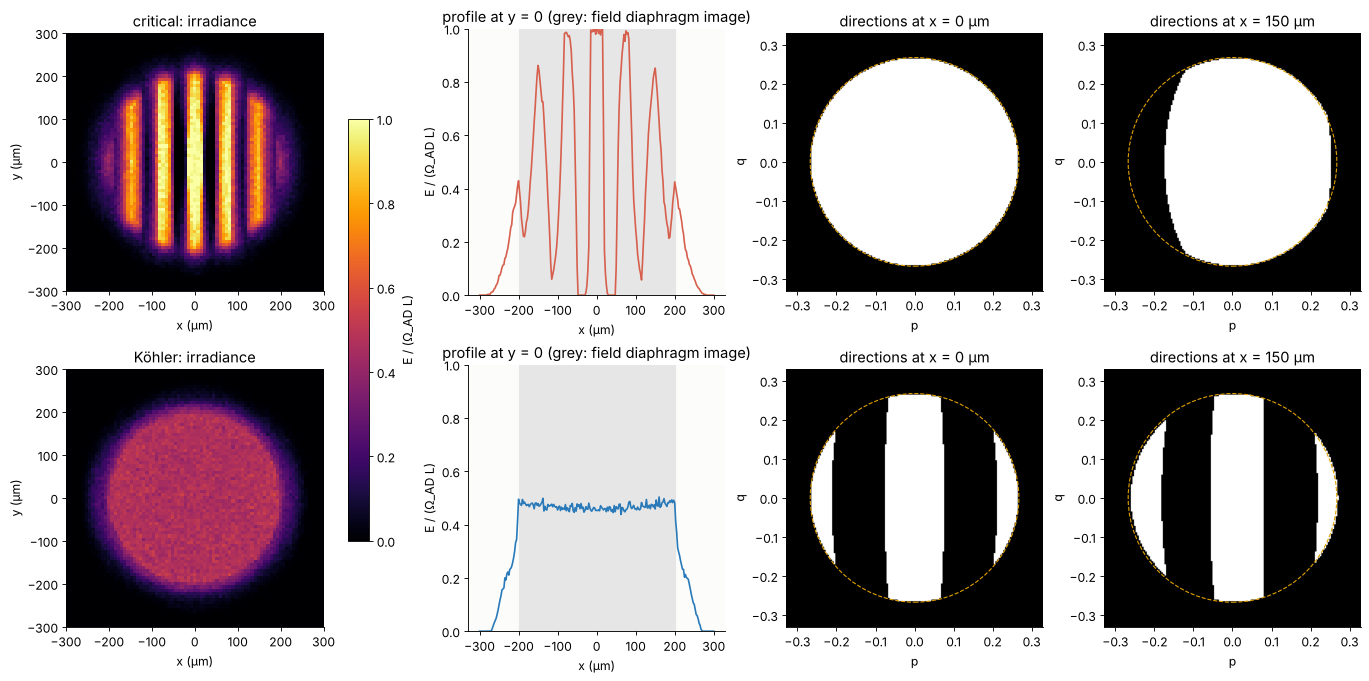

In [8]:
fig, ax = plt.subplots(2, 4, figsize=(17, 8.4), layout="constrained")
for row, name in enumerate(["critical", "Köhler"]):
    a = ax[row, 0]
    im = a.imshow(E_map[name]/omega_ad, extent=[-300, 300, -300, 300], origin="lower", cmap="inferno", vmin=0, vmax=1)
    a.set_title("{}: irradiance".format(name))
    a.set_xlabel("x (µm)")
    a.set_ylabel("y (µm)")
    a = ax[row, 1]
    a.plot(1e3*xp, E_prof[name]/omega_ad, color=RED if name == "critical" else BLUE)
    a.axvspan(-1e3*r_field, 1e3*r_field, color="0.9", zorder=0)
    a.set_ylim(0, 1)
    a.set_xlabel("x (µm)")
    a.set_ylabel("E / (Ω_AD L)")
    a.set_title("profile at y = 0 (grey: field diaphragm image)")
    for k, x0 in enumerate((0.0, 0.15)):
        a = ax[row, 2 + k]
        a.imshow(pupil_maps[name, x0], extent=[-NA_S, NA_S, -NA_S, NA_S], origin="lower", cmap="Greys_r", vmin=0, vmax=1)
        a.add_patch(plt.Circle((0, 0), NA_C, fill=False, color=ORANGE, lw=1, ls="--"))
        a.set_title("directions at x = {:.0f} µm".format(1e3*x0))
        a.set_xlabel("p")
        a.set_ylabel("q")
fig.colorbar(im, ax=ax[:, 0], shrink=0.7, label="E / (Ω_AD L)")
plt.show()

Critical illumination reproduces the filament on the specimen: seven
stripes 32 µm wide (0.25 mm × 1.30 × 0.1) with dark gaps, rms 80 % of the
mean. Seen from the specimen, a point on a ribbon looks into a fully lit
aperture diaphragm. At the centre of a gap the aperture is dark, and in
between it is partly lit. In Köhler illumination the field is flat to 2.2 %
rms in its central 70 %, close to the Monte Carlo noise of 6000
directions (1.4 %). Every point sees the same three ribbons in the aperture, the
filament image cut by the diaphragm. Off axis these slide sideways a
little.

The field ends at $|m|\,r_\text{FD} = 200$ µm, but not sharply: the edge
is spread over about 60 µm. The cause is coma of the condenser. It
violates the sine condition by $1 - 0.267/0.30 = 11$ %, and the coma at
the edge of the field scales with that offence against the sine condition
times the image height (notebook 102). Aplanatic condensers exist for
exactly this reason.

## 4. Phase space at the specimen

The radiance $L(x, p)$ along $x$ at $y = q = 0$, the phase space of
notebook 83 at the specimen plane.

In [9]:
xg = np.linspace(-0.3, 0.3, 241)
pg1 = np.linspace(-NA_S, NA_S, 241)
XG, PG = np.meshgrid(xg, pg1)
ps_maps = {}
for name, S, R in [("Köhler", koehler, Rk), ("critical", critical, Rc)]:
    L = il.backward_trace(S, np.column_stack([XG.ravel(), 0*XG.ravel()]), PG.ravel(), 0*PG.ravel(), filament,
                          reversed_system=R)
    ps_maps[name] = L.reshape(XG.shape)

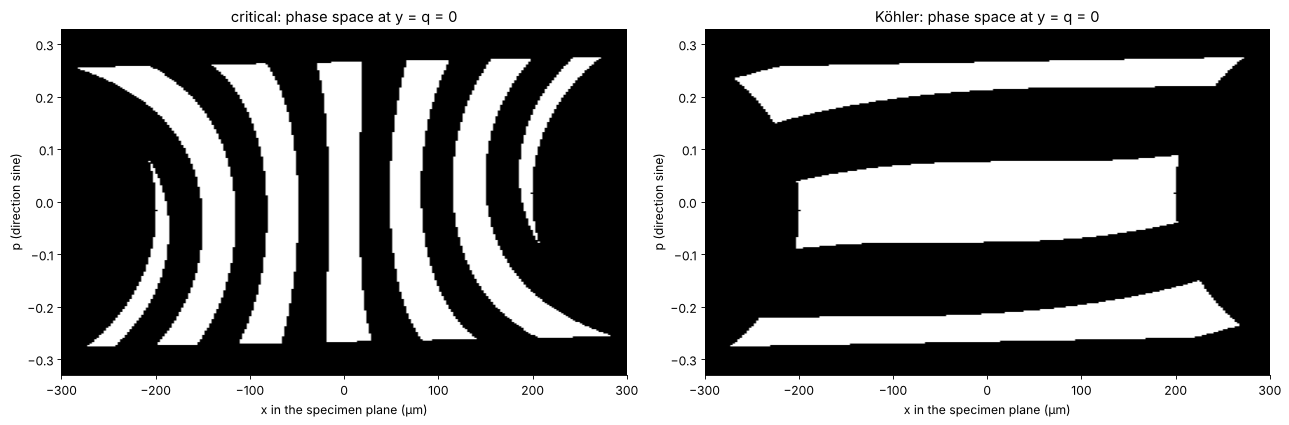

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2), layout="constrained")
for a, name in zip(ax, ["critical", "Köhler"]):
    a.imshow(ps_maps[name], extent=[-300, 300, -NA_S, NA_S], origin="lower", aspect="auto", cmap="Greys_r")
    a.set_xlabel("x in the specimen plane (µm)")
    a.set_ylabel("p (direction sine)")
    a.set_title("{}: phase space at y = q = 0".format(name))
plt.show()

The two settings are the same phase space portrait turned by 90°. Under
critical illumination position carries the filament: the stripes run along
$p$. They are curved by the residual aberrations of collector and field
lens, and cut at large $|p|$ by the aperture diaphragm. Under Köhler
illumination direction carries the filament: the stripes run along $x$,
cut at $|x| = 200$ µm by the field diaphragm. Köhler illumination does not
add étendue; it arranges the light so that the distribution of
directions, and with it the irradiance, is independent of position.

## 5. What each diaphragm does

In Köhler illumination the two diaphragms have separate jobs. We open the
aperture diaphragm from 0.5 to 5 mm (field diaphragm fixed at 2 mm) and
the field diaphragm from 0.5 to 4 mm (aperture diaphragm fixed at 3 mm),
and record the irradiance at the centre of the field and the radius of the
lit field (half maximum of a profile).

In [11]:
r_ads = np.linspace(0.5, 5.0, 10)
E_ad, omega_ads, fill_ad = [], [], []
centre = il.disk_points(100, 0.05, rng)
for r_ad in r_ads:
    S = illuminator(S_KOEHLER, r_fd=2.0, r_ad=r_ad)
    R = il.reverse_system(S)
    E_ad.append(il.backward_irradiance(S, centre, 0.55, filament, n_directions=4000, rng=rng, reversed_system=R).mean())
    omega_ads.append(il.backward_irradiance(S, np.zeros((1, 2)), 0.55, always, n_directions=100_000, rng=rng,
                                            reversed_system=R)[0])
    xa2, ya2 = xa*r_ad/3, ya*r_ad/3
    fill_ad.append(np.mean(filament(xa2[inside]/M_COLL_K, ya2[inside]/M_COLL_K)))
E_ad, omega_ads, fill_ad = map(np.array, (E_ad, omega_ads, fill_ad))
for r_ad, E, om, f in zip(r_ads, E_ad, omega_ads, fill_ad):
    print("r_AD = {:.1f} mm: Omega = {:.4f} (pi (r/f)^2 = {:.4f}), fill {:.3f}, E = {:.4f} L, fill*Omega = {:.4f} L"
          .format(r_ad, om, np.pi*(r_ad/10)**2, f, E, f*om))
r_fds = np.linspace(0.5, 4.0, 8)
field_r, E_fd = [], []
xq = np.linspace(0, 0.6, 121)
for r_fd in r_fds:
    S = illuminator(S_KOEHLER, r_fd=r_fd, r_ad=3.0)
    E = il.backward_irradiance(S, np.column_stack([xq, 0*xq]), NA_S, filament, n_directions=1500, rng=rng)
    field_r.append(np.interp(0.5, (E/E[0])[::-1], xq[::-1]))
    E_fd.append(E[0])
field_r, E_fd = np.array(field_r), np.array(E_fd)
print("FD scan: field radius (half maximum) / r_FD =", np.round(field_r/r_fds, 4), " |m| = {:.4f}".format(abs(M_COND)))
print("FD scan: centre irradiance / L =", np.round(E_fd, 4))

r_AD = 0.5 mm: Omega = 0.0078 (pi (r/f)^2 = 0.0079), fill 1.000, E = 0.0078 L, fill*Omega = 0.0078 L
r_AD = 1.0 mm: Omega = 0.0304 (pi (r/f)^2 = 0.0314), fill 0.878, E = 0.0274 L, fill*Omega = 0.0267 L
r_AD = 1.5 mm: Omega = 0.0651 (pi (r/f)^2 = 0.0707), fill 0.630, E = 0.0415 L, fill*Omega = 0.0410 L
r_AD = 2.0 mm: Omega = 0.1109 (pi (r/f)^2 = 0.1257), fill 0.483, E = 0.0556 L, fill*Omega = 0.0535 L
r_AD = 2.5 mm: Omega = 0.1634 (pi (r/f)^2 = 0.1963), fill 0.410, E = 0.0711 L, fill*Omega = 0.0670 L
r_AD = 3.0 mm: Omega = 0.2244 (pi (r/f)^2 = 0.2827), fill 0.448, E = 0.1036 L, fill*Omega = 0.1005 L
r_AD = 3.5 mm: Omega = 0.2853 (pi (r/f)^2 = 0.3848), fill 0.501, E = 0.1425 L, fill*Omega = 0.1429 L
r_AD = 4.0 mm: Omega = 0.3451 (pi (r/f)^2 = 0.5027), fill 0.543, E = 0.1827 L, fill*Omega = 0.1873 L
r_AD = 4.5 mm: Omega = 0.4073 (pi (r/f)^2 = 0.6362), fill 0.530, E = 0.2094 L, fill*Omega = 0.2157 L
r_AD = 5.0 mm: Omega = 0.4655 (pi (r/f)^2 = 0.7854), fill 0.505, E = 0.2305 L, fill*Omega =

FD scan: field radius (half maximum) / r_FD = [0.1069 0.106  0.1066 0.1103 0.1122 0.1103 0.1091 0.1074]  |m| = 0.1000
FD scan: centre irradiance / L = [0.1115 0.104  0.1001 0.1056 0.1022 0.0988 0.0994 0.1031]


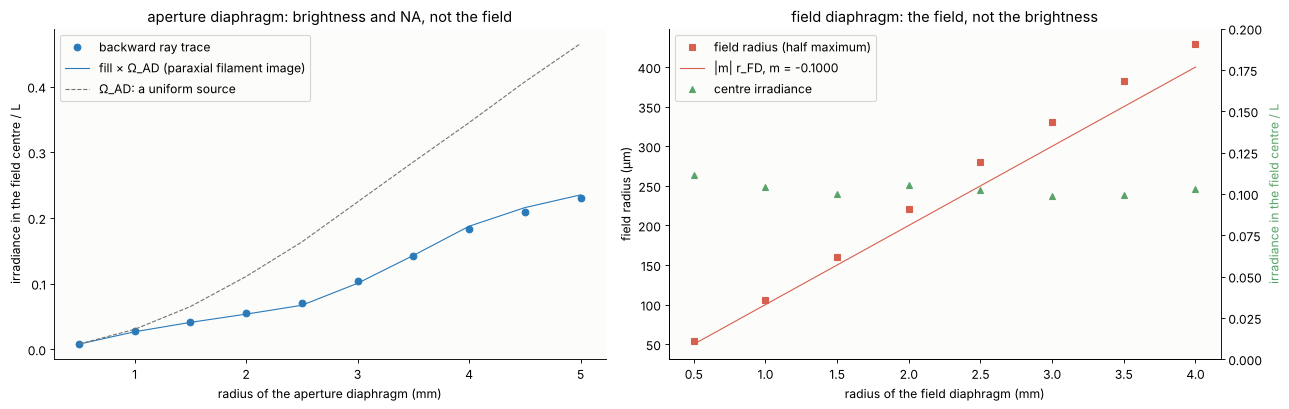

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
ax[0].plot(r_ads, E_ad, "o", color=BLUE, label="backward ray trace")
ax[0].plot(r_ads, fill_ad*omega_ads, "-", color=BLUE, lw=1, label="fill × Ω_AD (paraxial filament image)")
ax[0].plot(r_ads, omega_ads, "--", color=GREY, lw=1, label="Ω_AD: a uniform source")
ax[0].set_xlabel("radius of the aperture diaphragm (mm)")
ax[0].set_ylabel("irradiance in the field centre / L")
ax[0].set_title("aperture diaphragm: brightness and NA, not the field")
ax[0].legend()
ax[1].plot(r_fds, 1e3*field_r, "s", color=RED, label="field radius (half maximum)")
ax[1].plot(r_fds, 1e3*abs(M_COND)*r_fds, "-", color=RED, lw=1, label="|m| r_FD, m = {:.4f}".format(M_COND))
ax[1].set_xlabel("radius of the field diaphragm (mm)")
ax[1].set_ylabel("field radius (µm)")
tw = ax[1].twinx()
tw.plot(r_fds, E_fd, "^", color=GREEN, label="centre irradiance")
tw.set_ylim(0, 0.2)
tw.set_ylabel("irradiance in the field centre / L", color=GREEN)
tw.spines["right"].set_visible(True)
ax[1].set_title("field diaphragm: the field, not the brightness")
h1, l1 = ax[1].get_legend_handles_labels()
h2, l2 = tw.get_legend_handles_labels()
ax[1].legend(h1 + h2, l1 + l2, loc="upper left")
plt.show()

**Aperture diaphragm:** the irradiance grows with the diaphragm, but not
as $\Omega_\text{AD}$. As long as the diaphragm lies within the image of
the central ribbon (below about 0.8 mm) the fill is 1. Beyond it, the gaps
of the filament image come in and the fill drops to 41 %. $\text{fill}\cdot\Omega_\text{AD}$
follows the trace within 6 %. The diaphragm sets the illumination NA (the
coherence parameter $\sigma$ of notebook 52) and with it the brightness,
not the field.

**Field diaphragm:** the field radius grows as $|m|\,r_\text{FD}$; the
6 to 12 % excess is the coma tail of section 3. The irradiance at the centre
stays at $0.10\,L$ within the Monte Carlo noise. The diaphragm sets what is
lit, not how brightly. In a microscope, closing it to the field of view
keeps stray light out of the image, without dimming it.

## 6. From Köhler to critical: focusing the lamp

Moving the lamp from the Köhler position (23.0 mm) to the critical one
(35.4 mm) sweeps the filament image from the aperture diaphragm to the
field diaphragm. We follow the non-uniformity over the central ±150 µm of
the field.

In [13]:
lamp = np.linspace(S_KOEHLER, S_CRIT, 9)
xu = np.linspace(-0.15, 0.15, 61)
unif = []
for s_lamp in lamp:
    E = il.backward_irradiance(illuminator(s_lamp), np.column_stack([xu, 0*xu]), NA_S, filament, n_directions=3000, rng=rng)
    unif.append((E.std()/E.mean(), E.mean()))
unif = np.array(unif)
for s_lamp, (u, m) in zip(lamp, unif):
    print("lamp at {:.2f} mm: rms/mean over ±150 µm {:.1%}, mean E {:.4f} L".format(s_lamp, u, m))

lamp at 23.02 mm: rms/mean over ±150 µm 2.7%, mean E 0.1042 L
lamp at 24.57 mm: rms/mean over ±150 µm 3.2%, mean E 0.0994 L
lamp at 26.11 mm: rms/mean over ±150 µm 7.4%, mean E 0.1049 L
lamp at 27.66 mm: rms/mean over ±150 µm 15.3%, mean E 0.1147 L
lamp at 29.20 mm: rms/mean over ±150 µm 22.8%, mean E 0.1197 L
lamp at 30.75 mm: rms/mean over ±150 µm 37.6%, mean E 0.1154 L
lamp at 32.29 mm: rms/mean over ±150 µm 59.2%, mean E 0.1077 L
lamp at 33.84 mm: rms/mean over ±150 µm 71.6%, mean E 0.1067 L
lamp at 35.38 mm: rms/mean over ±150 µm 75.3%, mean E 0.1134 L


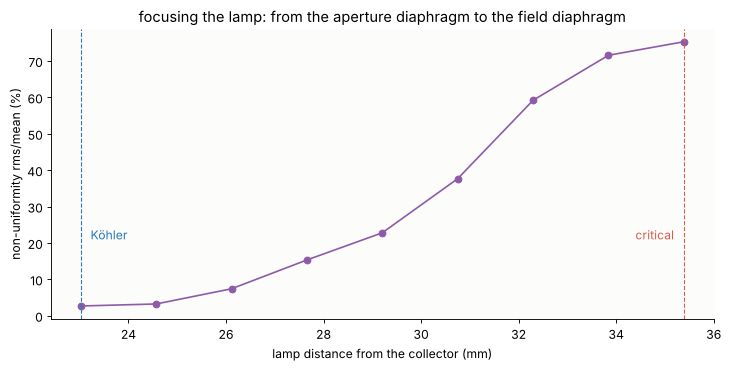

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.plot(lamp, 100*unif[:, 0], "o-", color=PURPLE)
ax.axvline(S_KOEHLER, color=BLUE, ls="--", lw=1)
ax.axvline(S_CRIT, color=RED, ls="--", lw=1)
ax.text(S_KOEHLER + 0.2, 21, "Köhler", color=BLUE)
ax.text(S_CRIT - 0.2, 21, "critical", color=RED, ha="right")
ax.set_xlabel("lamp distance from the collector (mm)")
ax.set_ylabel("non-uniformity rms/mean (%)")
ax.set_title("focusing the lamp: from the aperture diaphragm to the field diaphragm")
plt.show()

The field stays even (below 4 %) for about 1.5 mm around the Köhler
position. Then the filament stripes appear and grow steadily until they
reach the full contrast of critical illumination. In practice the lamp is
focused by looking at the filament image on a closed aperture diaphragm,
or in the back focal plane of the objective through a Bertrand lens.

## 7. Images of a Siemens star

The two illuminations as a microscope sees them. A Siemens star of 36
absorbing spokes (amplitude transmission 0.2) on a clear slide is imaged
by an objective of NA 0.4 at 550 nm (`mic.abbe_image()`). The plane waves
come from:

- **Köhler:** the illumination directions traced backwards from the
  centre of the field, a source point wherever $L(p, q) > 0$.
- **uniform aperture diaphragm:** for comparison, the same diaphragm
  filled uniformly.

Under critical illumination every specimen point sees the aperture
diaphragm fully lit, or partly dark in the gaps. The irradiance changes
over 30 µm and more, slowly compared with the resolution of under 1 µm, so it
multiplies the image of the uniform diaphragm. The images are scaled by
the irradiance maps of section 3.

In [15]:
WL, NA_OBJ, N7 = 550e-6, 0.4, 512
x7, y7, X7, Y7 = grid2d(-0.08, 0.08, -0.08, 0.08, N7)
th7 = np.arctan2(Y7, X7)
spokes = (np.hypot(X7, Y7) < 0.06) & (np.cos(36*th7) > 0)
star = np.where(spokes, 0.2, 1.0)          # Siemens star of 36 absorbing spokes (20 % amplitude) on a clear slide
# illumination directions at the field centre on a grid of 4 x 4 frequency samples
dna = 4*WL/(x7[-1] - x7[0] + x7[1] - x7[0])
g = np.arange(-np.ceil(NA_C/dna), np.ceil(NA_C/dna) + 1)*dna
GP, GQ = [a.ravel() for a in np.meshgrid(g, g)]
L_k = il.backward_trace(koehler, np.zeros((GP.size, 2)), GP, GQ, filament, reversed_system=Rk)
T_ad = il.backward_trace(koehler, np.zeros((GP.size, 2)), GP, GQ, always, reversed_system=Rk)
src_k = mic.source_points(x7, y7, WL, 0, points=np.column_stack([GP, GQ])[L_k > 0], weights=L_k[L_k > 0])
src_u = mic.source_points(x7, y7, WL, 0, points=np.column_stack([GP, GQ])[T_ad > 0], weights=T_ad[T_ad > 0])
print("source points: Köhler (filament image) {}, uniform aperture {}".format(len(src_k[2]), len(src_u[2])))
img_k = mic.abbe_image(star, x7, y7, WL, NA_OBJ, source=src_k)
img_u = mic.abbe_image(star, x7, y7, WL, NA_OBJ, source=src_u)
# critical: every specimen point sees the AD filled where the filament image covers it; the
# irradiance varies over ~70 µm, slowly compared with the resolution, so it multiplies the image
from scipy.interpolate import RegularGridInterpolator
E_crit = RegularGridInterpolator((xs, xs), E_map["critical"].T)(np.column_stack([X7.ravel(), Y7.ravel()])).reshape(X7.shape)
E_koeh = RegularGridInterpolator((xs, xs), E_map["Köhler"].T)(np.column_stack([X7.ravel(), Y7.ravel()])).reshape(X7.shape)
img_c = img_u*E_crit/omega_ad
img_kE = img_k*E_koeh/omega_ad
print("image of the star, Köhler with the filament pupil vs a uniformly filled AD: rms difference {:.1%} of the mean"
      .format(np.std(img_k - img_u)/img_u.mean()))
print("brightness across the window (relative rms): Köhler {:.1%}, critical {:.1%}"
      .format(np.std(E_koeh)/E_koeh.mean(), np.std(E_crit)/E_crit.mean()))

source points: Köhler (filament image) 561, uniform aperture 1201


image of the star, Köhler with the filament pupil vs a uniformly filled AD: rms difference 0.9% of the mean
brightness across the window (relative rms): Köhler 3.9%, critical 75.8%


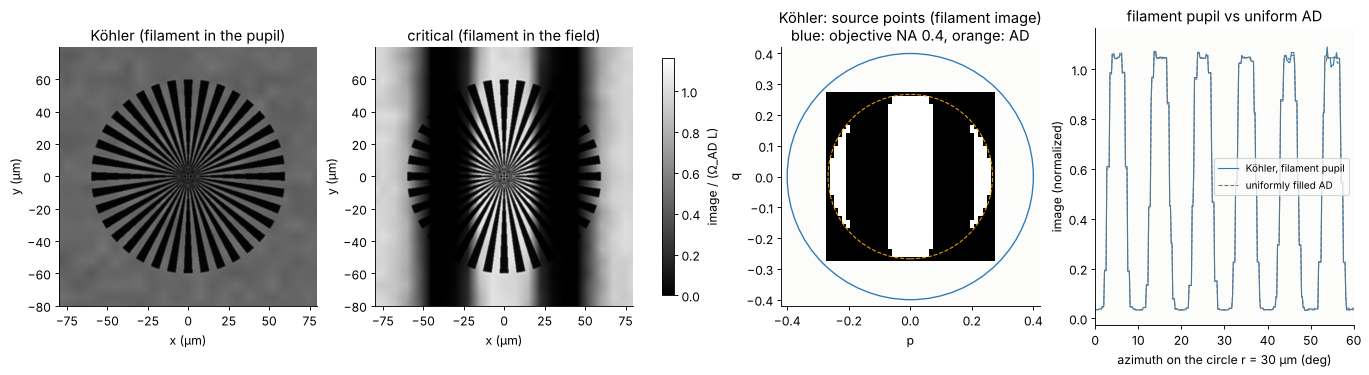

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.6), layout="constrained")
ext = [1e3*x7[0], 1e3*x7[-1], 1e3*y7[0], 1e3*y7[-1]]
vmax = max(img_kE.max(), img_c.max())
for a, im_, ttl in [(ax[0], img_kE, "Köhler (filament in the pupil)"),
                    (ax[1], img_c, "critical (filament in the field)")]:
    h = a.imshow(im_, extent=ext, origin="lower", cmap="gray", vmin=0, vmax=vmax)
    a.set_title(ttl)
    a.set_xlabel("x (µm)")
    a.set_ylabel("y (µm)")
fig.colorbar(h, ax=ax[:2], shrink=0.8, label="image / (Ω_AD L)")
a = ax[2]
a.imshow(L_k.reshape(len(g), len(g)), extent=[g[0], g[-1], g[0], g[-1]], origin="lower", cmap="Greys_r")
a.add_patch(plt.Circle((0, 0), NA_OBJ, fill=False, color=BLUE, lw=1.2))
a.add_patch(plt.Circle((0, 0), NA_C, fill=False, color=ORANGE, lw=1.0, ls="--"))
a.set_xlim(-NA_OBJ*1.05, NA_OBJ*1.05)
a.set_ylim(-NA_OBJ*1.05, NA_OBJ*1.05)
a.set_title("Köhler: source points (filament image)\nblue: objective NA {}, orange: AD".format(NA_OBJ))
a.set_xlabel("p")
a.set_ylabel("q")
a = ax[3]
r_line = 0.03
ang = np.linspace(0, 2*np.pi, 2000)
iy, ix = [np.clip(np.round((r_line*f(ang) - x7[0])/(x7[1] - x7[0])).astype(int), 0, N7 - 1) for f in (np.sin, np.cos)]
a.plot(np.degrees(ang), img_k[iy, ix], color=BLUE, lw=1, label="Köhler, filament pupil")
a.plot(np.degrees(ang), img_u[iy, ix], color=GREY, lw=1, ls="--", label="uniformly filled AD")
a.set_xlim(0, 60)
a.set_xlabel("azimuth on the circle r = 30 µm (deg)")
a.set_ylabel("image (normalized)")
a.set_title("filament pupil vs uniform AD")
a.legend(loc="center right", fontsize=9)
plt.show()

Under critical illumination the filament stripes lie across the star and
dominate the picture: the irradiance across the window varies by 76 % rms,
against 4 % under Köhler illumination, which is the Monte Carlo noise of
the 600-direction irradiance map (4.5 %).
That the Köhler pupil is three stripes and not a full disk changes the
image by only 0.9 % rms. Partial coherence depends on the spread of
illumination directions, not on whether the spread is uniform, as long as
the pupil has no large holes. This is the practical case for Köhler
illumination: an even field from a structured lamp, and the image quality
of a filled aperture.

## Summary

- **Backward ray tracing** (`il.reverse_system()`, `il.backward_trace()`,
  `il.backward_irradiance()`) computes irradiance as
  $E = \int L\,dp\,dq$ over the directions arriving at a point, each ray
  carrying the radiance of the source point it comes from. It agrees with
  forward Monte Carlo within its 2 % error, and it needs no rays wasted on
  the diaphragms.
- **Critical illumination** images the filament onto the specimen: stripes
  with 80 % rms.
- **Köhler illumination** puts the filament image into the aperture
  diaphragm. The field is flat within 2 %, and every point sees the same
  pupil.
- **Phase space:** the two settings are the same portrait turned by 90°,
  with the filament on the position axis (critical) or on the direction
  axis (Köhler).
- **Étendue budget:** $E = \text{fill}\cdot\Omega_\text{AD}L$, accurate to
  3 %. The rim NA of 0.267 instead of $r/f = 0.30$ is the hyperbolic
  condenser's violation of the sine condition, which also blurs the edge
  of the field with coma.
- **Diaphragms:** the aperture diaphragm sets the NA and the brightness,
  the field diaphragm the lit field ($|m|\,r_\text{FD}$). Neither affects
  what the other controls.
- **Images:** critical illumination stripes the image of a Siemens star.
  The structured Köhler pupil changes it by under 1 % from a uniformly
  filled one.

In [17]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 49 s


## References

- A. Köhler, "Ein neues Beleuchtungsverfahren für mikrophotographische Zwecke", Z. wiss. Mikrosk. 10, 433-440 (1893).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge University Press (1999), section 10.6.2 (partially coherent imaging with Köhler and critical illumination).
- H. H. Hopkins and P. M. Barham, "The influence of the condenser on microscopic resolution", Proc. Phys. Soc. B 63, 737-744 (1950).
- J. Mertz, *Introduction to Optical Microscopy*, 2nd ed., Cambridge University Press (2019), ch. 6.
- D. B. Murphy and M. W. Davidson, *Fundamentals of Light Microscopy and Electronic Imaging*, 2nd ed., Wiley-Blackwell (2012), ch. 1.
- J. Chaves, *Introduction to Nonimaging Optics*, 2nd ed., CRC Press (2016), ch. 21 (Köhler integration).